# Machine Learning Pipeline for Breast Cancer Diagnosis (WDBC)

Our aim is to predict whether a breast mass is malignant (positive class, 1) or benign (0) from 30 numeric features computed from digitised fine-needle-aspirate images (Wisconsin Diagnostic Breast Cancer dataset, UCI).

Changes done in this revised version: In the first version the data was scaled and ran supervised feature selection on the whole training set before cross-validation, so validation labels influenced which features were kept. Now every data-dependent step (scaling, feature selection, classifier) is inside the scikit-learn Pipeline and is fitted again on the training part of each fold. The test set (20 %) is only used once, at the very end. By this was I avoided leakage.

Three different kinds of numbers appear in this notebook; they are never mixed:

| Section | Experiment | Features | Evaluated with | Reported as |
|---|---|---|---|---|
| 4 | Feature-selection study (Logistic Regression) | 30 vs. several subsets | repeated 5x3 stratified CV on the training set | CV accuracy |
| 5.1 | Default models | all 30 | repeated 5x3 stratified CV on the training set | CV accuracy |
| 5.4 | Tuned models (`GridSearchCV`) | all 30 **and** reduced set (correlation filter, |r| <= 0.90) | held-out test set (114 samples) | test metrics |

Everything is reproducible: `random_state=42` is used throughout, and the two custom selectors are defined in the first code cell.

In [1]:
import os, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     GridSearchCV, RandomizedSearchCV, cross_val_score, ParameterGrid)
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, RFE, f_classif
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef,
                             roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay)

from sklearn.base import BaseEstimator, TransformerMixin

# two custom feature selectors (used inside Pipelines, so they only ever see the training part of a fold)
# IntersectionSelector: keeps the features chosen by both SelectKBest and RFE.
# CorrelationFilter: visits features from most to least discriminative and keeps a feature only if
# its |Pearson r| with every already kept feature is <= threshold.
class IntersectionSelector(BaseEstimator, TransformerMixin):

    def __init__(self, k_kbest=16, k_rfe=16):
        self.k_kbest = k_kbest
        self.k_rfe = k_rfe

    def fit(self, X, y):
        kbest = SelectKBest(f_classif, k=self.k_kbest).fit(X, y)
        rfe = RFE(LogisticRegression(max_iter=5000), n_features_to_select=self.k_rfe).fit(X, y)
        self.mask_ = kbest.get_support() & rfe.get_support()
        return self

    def transform(self, X):
        return np.asarray(X)[:, self.mask_]

    def get_support(self):
        return self.mask_


class CorrelationFilter(BaseEstimator, TransformerMixin):
    """Greedy redundancy filter added in this.

    Features are visited from the most to the least discriminative according to ANOVA F-score;
    a feature is kept only if its absolute Pearson correlation with every feature
    already kept is <= threshold. no kept pair is correlated above the threshold.
    """

    def __init__(self, threshold=0.9):
        self.threshold = threshold

    def fit(self, X, y):
        X = np.asarray(X)
        scores, _ = f_classif(X, y)
        corr = np.abs(np.corrcoef(X, rowvar=False))
        kept = []
        for j in np.argsort(-scores):
            if all(corr[j, i] <= self.threshold for i in kept):
                kept.append(j)
        self.mask_ = np.zeros(X.shape[1], dtype=bool)
        self.mask_[kept] = True
        return self

    def transform(self, X):
        return np.asarray(X)[:, self.mask_]

    def get_support(self):
        return self.mask_

warnings.filterwarnings('ignore')
SEED = 42
pd.set_option('display.precision', 3)
pd.set_option('display.width', 140)
sns.set_theme(style='whitegrid')
CLASS_COLORS = {'Benign': '#6baed6', 'Malignant': '#fb8072'}
for folder in ['plots', 'models', 'results']:
    os.makedirs(folder, exist_ok=True)

## 1. Loading the data

The 30 features are 10 nucleus properties (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), and each of them are given as the mean, the standard error (se) and the worst value over the nuclei in one image. There are no missing values, and the classes are imbalanced (62.7 % benign, 37.3 % malignant).

In [2]:
base_props = ['radius', 'texture', 'perimeter', 'area', 'smoothness',
              'compactness', 'concavity', 'concave_points', 'symmetry', 'fractal_dimension']
stats = ['mean', 'se', 'worst']
feature_names = [f'{p}_{s}' for s in stats for p in base_props]      # same column order as wdbc.data

raw = pd.read_csv('data/wdbc.data', header=None, names=['id', 'diagnosis'] + feature_names)
data = raw.drop(columns='id')
data['diagnosis'] = data['diagnosis'].map({'B': 0, 'M': 1})          # 1 = malignant (positive class)

n_b, n_m = (data.diagnosis == 0).sum(), (data.diagnosis == 1).sum()
print(f'{len(data)} samples, {len(feature_names)} numeric features, {int(data.isna().sum().sum())} missing values')
print(f'Benign: {n_b} ({n_b/len(data):.1%})   Malignant: {n_m} ({n_m/len(data):.1%})')

569 samples, 30 numeric features, 0 missing values
Benign: 357 (62.7%)   Malignant: 212 (37.3%)


## 2. Train/test split

The split is done first, stratified so both parts keep the class ratio. All exploration below uses the training set only, so nothing learned from the test samples can influence feature or model decisions. Scaling is not done here: it is part of every pipeline and is fitted inside each training fold.

In [3]:
X = data[feature_names].values
y = data['diagnosis'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
train_df = pd.DataFrame(X_train, columns=feature_names).assign(diagnosis=y_train)
train_df['label'] = train_df['diagnosis'].map({0: 'Benign', 1: 'Malignant'})

print(f'Train: {X_train.shape[0]} samples ({y_train.mean():.1%} malignant)')
print(f'Test : {X_test.shape[0]} samples ({y_test.mean():.1%} malignant = {y_test.sum()} malignant cases)')

Train: 455 samples (37.4% malignant)
Test : 114 samples (36.8% malignant = 42 malignant cases)


## 3. Exploratory data analysis

Instead of plotting every feature, the figures below were chosen to answer specific questions: how skewed are the features, which ones separate the classes, and how redundant is the feature set.

### 3.1 Scales

The features live on very different scales: `area_mean` has a standard deviation of about 360 while `smoothness_mean` is about 0.014, and `fractal_dimension_se` is of order 0.001. Distance- and gradient-based methods (k-NN, SVM, Logistic Regression) would be dominated by the large-scale features, so every pipeline starts with `StandardScaler`.

In [4]:
summary = train_df[feature_names].describe().T[['mean', 'std', 'min', 'max']]
summary.loc[['area_mean', 'area_worst', 'perimeter_mean', 'radius_mean', 'smoothness_mean', 'fractal_dimension_se']]

,mean,std,min,max
area_mean,659.578,360.419,1.435e+02,2501.000
area_worst,890.569,582.346,1.852e+02,4254.000
perimeter_mean,92.216,24.717,4.379e+01,188.500
radius_mean,14.166,3.579,6.981e+00,28.110
smoothness_mean,0.096,0.014,6.251e-02,0.163
fractal_dimension_se,0.004,0.003,8.948e-04,0.030


### 3.2 Skewness

Skewness: top 8 features
area_se                 5.50
concavity_se            5.39
fractal_dimension_se    4.09
perimeter_se            3.52
radius_se               3.18
smoothness_se           2.46
symmetry_se             2.25
area_worst              1.90

Features with skew > 1: 23 of 30  (mean: 6, se: 10, worst: 7)


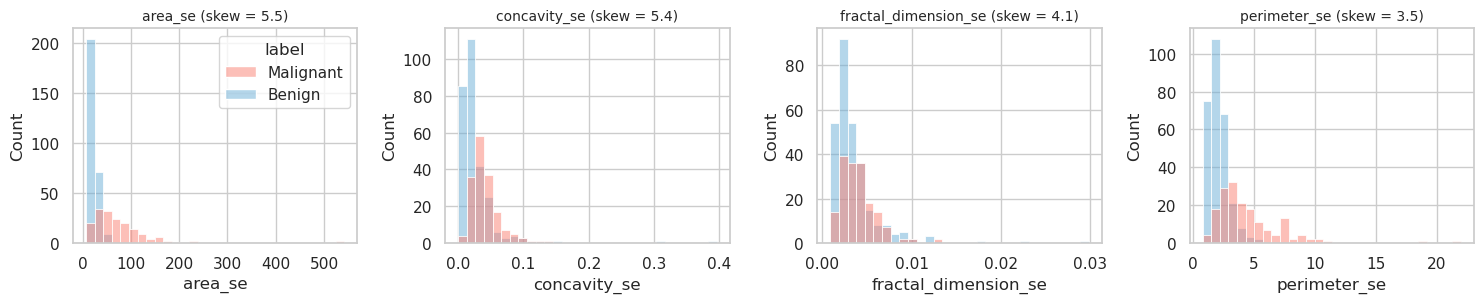

In [5]:
skew = train_df[feature_names].skew().sort_values(ascending=False)
print('Skewness: top 8 features')
print(skew.head(8).round(2).to_string())
print(f'\nFeatures with skew > 1: {(skew > 1).sum()} of 30  '
      f'(mean: {(skew[[f for f in skew.index if f.endswith("_mean")]] > 1).sum()}, '
      f'se: {(skew[[f for f in skew.index if f.endswith("_se")]] > 1).sum()}, '
      f'worst: {(skew[[f for f in skew.index if f.endswith("_worst")]] > 1).sum()})')

top_skew = list(skew.index[:4])
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, f in zip(axes, top_skew):
    sns.histplot(data=train_df, x=f, hue='label', palette=CLASS_COLORS, bins=30, ax=ax, legend=(f == top_skew[0]))
    ax.set_title(f'{f} (skew = {skew[f]:.1f})', fontsize=10)
plt.tight_layout()
plt.show()

23 of the 30 features have a skewness above 1. The most extreme are `area_se` (5.5), `concavity_se` (5.4) and `fractal_dimension_se` (4.1): most images have small standard errors, and a few have very large ones. Consequences: (1) the *se* features contain many high outliers, which standardisation does not remove, so scale-sensitive models can be affected by them; (2) tree-based models are unaffected by skew.

### 3.3 Differences between the diagnostic classes

For each feature, Cohen's d measures the standardised difference between the malignant and benign means (|d| > 0.8 is conventionally "large").

Most discriminative features (largest |d|):
                         d  skew  outliers (benign)  outliers (malignant)
concave_points_worst  2.62  0.49                  2                     1
perimeter_worst       2.60  1.14                  2                     3
radius_worst          2.55  1.12                  2                     1
concave_points_mean   2.54  1.20                 12                     6
perimeter_mean        2.27  1.04                  3                     3
area_worst            2.21  1.90                  3                     7

Least discriminative features:
                           d  skew  outliers (benign)  outliers (malignant)
smoothness_se          -0.12  2.46                 12                     4
texture_se             -0.01  1.81                  8                     6
symmetry_se             0.01  2.25                  7                    13
fractal_dimension_mean  0.01  1.26                 13                     1


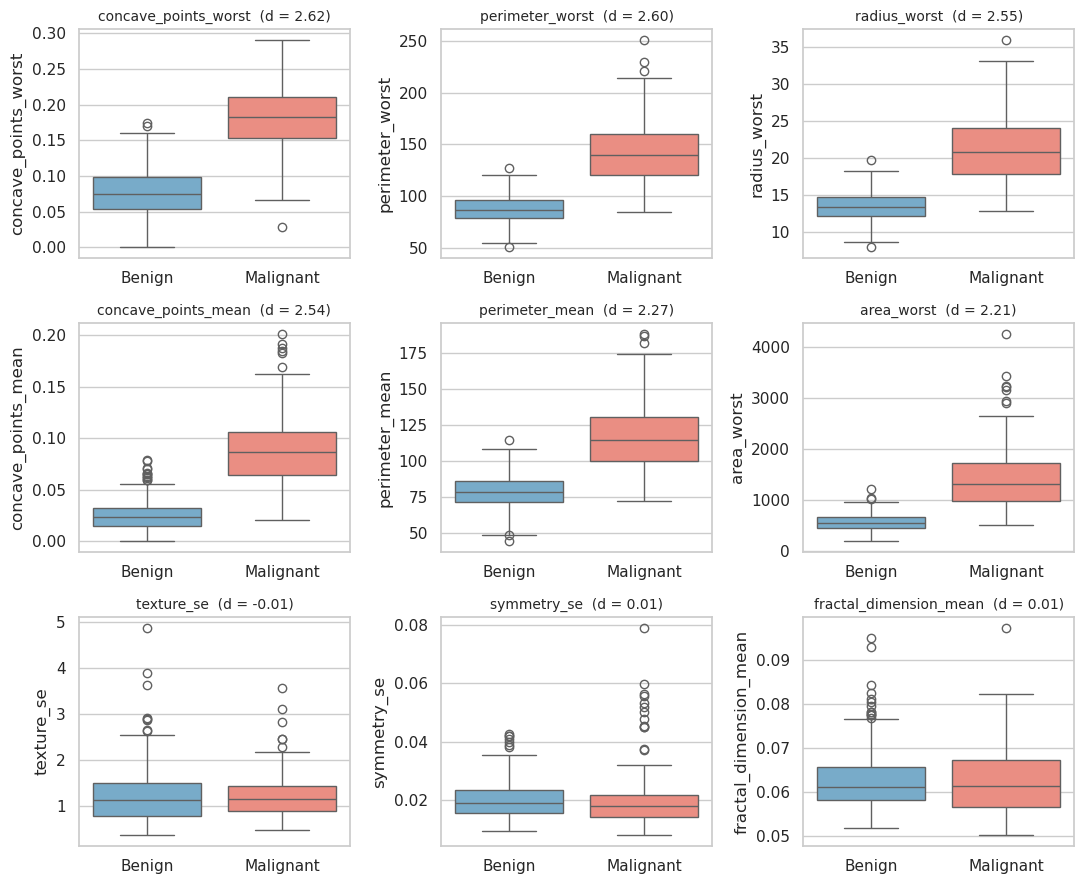

In [6]:
def cohens_d(a, b):
    """Standardised mean difference between malignant (a) and benign (b)."""
    pooled = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / pooled

def n_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

m, b = train_df[train_df.diagnosis == 1], train_df[train_df.diagnosis == 0]
effect = pd.DataFrame({
    'd': {f: cohens_d(m[f], b[f]) for f in feature_names},
    'skew': skew,
    'outliers (benign)': {f: n_outliers(b[f]) for f in feature_names},
    'outliers (malignant)': {f: n_outliers(m[f]) for f in feature_names},
})
effect = effect.loc[effect['d'].abs().sort_values(ascending=False).index]   # d = Cohen's d (malignant vs benign)
print('Most discriminative features (largest |d|):')
print(effect.head(6).round(2).to_string())
print('\nLeast discriminative features:')
print(effect.tail(4).round(2).to_string())

shown = list(effect.index[:6]) + list(effect.index[-3:])
fig, axes = plt.subplots(3, 3, figsize=(11, 9))
for ax, f in zip(axes.ravel(), shown):
    sns.boxplot(data=train_df, x='label', y=f, order=['Benign', 'Malignant'], palette=CLASS_COLORS, ax=ax)
    ax.set_title(f"{f}  (d = {effect.loc[f, 'd']:.2f})", fontsize=10)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

The six most discriminative features are all about *size and shape irregularity* of the nuclei: `concave_points_worst`, `perimeter_worst`, `radius_worst`, `concave_points_mean`, `perimeter_mean` and `area_worst`, with |d| between 2.2 and 2.6. For these the boxes of the two classes barely overlap; malignant nuclei are larger and have more concave contour points. Malignant cases also show more high outliers (e.g. 7 for `area_worst` against 3 in benign), which reflects the heterogeneity of malignant tumours. On the other end, `texture_se`, `symmetry_se`, `fractal_dimension_mean` and `smoothness_se` have |d| close to 0: their distributions are nearly identical in the two classes, so on their own they carry little diagnostic information, they have many outliers but the outliers do not separate the classes.

Feature pairs with |r| > 0.90: 21   |r| > 0.95: 15   (of 435 pairs)
      feature 1       feature 2     r   |r|
    radius_mean  perimeter_mean 0.998 0.998
   radius_worst perimeter_worst 0.994 0.994
    radius_mean       area_mean 0.987 0.987
 perimeter_mean       area_mean 0.986 0.986
   radius_worst      area_worst 0.983 0.983
perimeter_worst      area_worst 0.977 0.977
      radius_se    perimeter_se 0.975 0.975
 perimeter_mean perimeter_worst 0.970 0.970


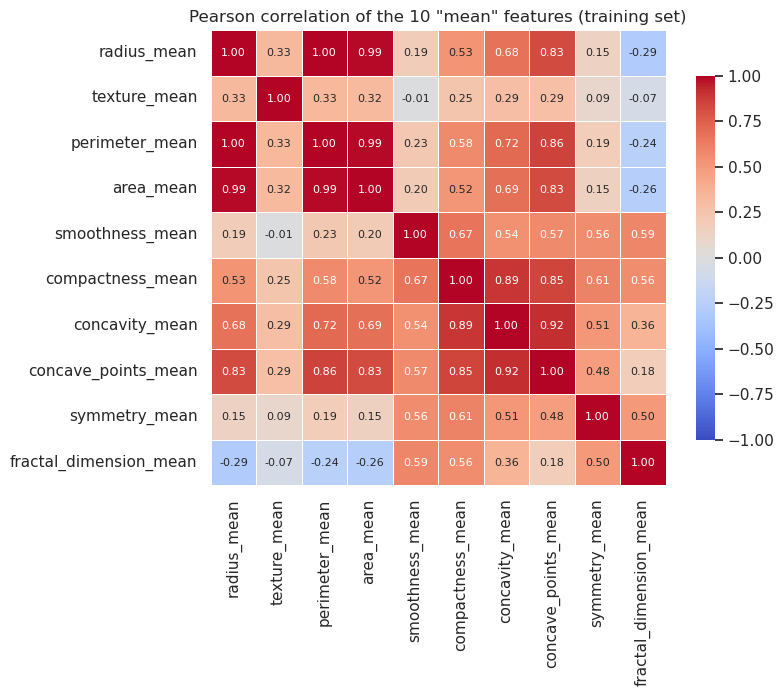

In [7]:
corr = train_df[feature_names].corr()
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
             .rename('r').reset_index().rename(columns={'level_0': 'feature 1', 'level_1': 'feature 2'}))
pairs['|r|'] = pairs['r'].abs()
pairs = pairs.sort_values('|r|', ascending=False)
print(f'Feature pairs with |r| > 0.90: {(pairs["|r|"] > 0.90).sum()}   |r| > 0.95: {(pairs["|r|"] > 0.95).sum()}   (of {len(pairs)} pairs)')
print(pairs.head(8).round(3).to_string(index=False))

mean_cols = [f'{p}_mean' for p in base_props]
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(train_df[mean_cols].corr(), cmap='coolwarm', vmin=-1, vmax=1, center=0, annot=True, fmt='.2f',
            annot_kws={'size': 8}, square=True, linewidths=.5, cbar_kws={'shrink': .8}, ax=ax)
ax.set_title('Pearson correlation of the 10 "mean" features (training set)')
plt.tight_layout()
plt.show()

### 3.4 Redundancy between features

There are 21 feature pairs with |r| > 0.90 and 15 with |r| > 0.95. The strongest are geometric by construction: `radius_mean`-`perimeter_mean` (0.998), `radius_worst`-`perimeter_worst` (0.994), and the radius/perimeter/area triples within mean, se and worst. In addition, each "mean" feature is strongly correlated with its own "worst" version (e.g. `perimeter_mean`-`perimeter_worst`, 0.97). In the heatmap, the block of radius, perimeter, area, concavity and concave points is clearly visible. This is redundancy: these columns carry almost the same information, which inflates coefficient variance in linear models and makes individual coefficients hard to interpret, but it hurts prediction accuracy much less. Section 4 checks whether feature selection actually removes this redundancy.

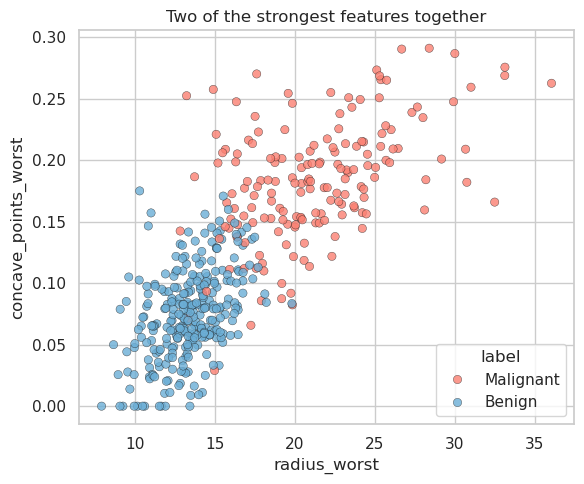

In [8]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.scatterplot(data=train_df, x='radius_worst', y='concave_points_worst', hue='label', palette=CLASS_COLORS,
                alpha=.8, edgecolor='k', linewidth=.3, ax=ax)
ax.set_title('Two of the strongest features together')
plt.tight_layout()
plt.show()

The scatter plot shows that two of the strongest features already separate most cases, with a small overlap zone.

### 3.5 PCA

PCA is fitted on the scaled training data without using the labels and serves only to look at the data, not as a modelling step.

PC1 explains 44.6%, PC1+PC2 63.1%; 10 components are needed for 95% of the variance


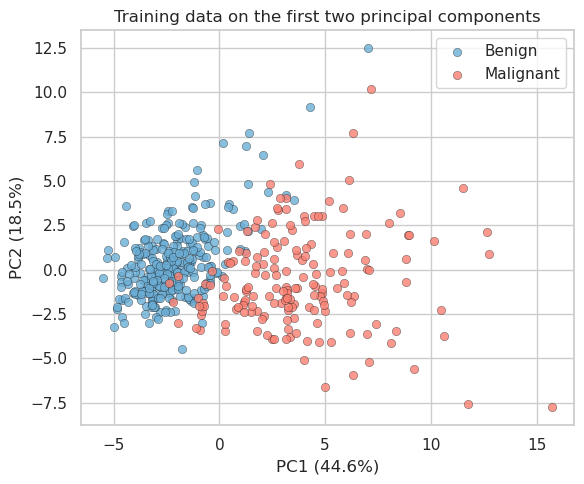

In [9]:
pca = PCA().fit(StandardScaler().fit_transform(X_train))          # unsupervised, training data only
cum = np.cumsum(pca.explained_variance_ratio_)
print(f'PC1 explains {pca.explained_variance_ratio_[0]:.1%}, PC1+PC2 {cum[1]:.1%}; '
      f'{np.argmax(cum >= 0.95) + 1} components are needed for 95% of the variance')

Z = pca.transform(StandardScaler().fit_transform(X_train))[:, :2]
fig, ax = plt.subplots(figsize=(6, 5))
for label, color in CLASS_COLORS.items():
    mask = (train_df['label'] == label).values
    ax.scatter(Z[mask, 0], Z[mask, 1], c=color, label=label, alpha=.8, edgecolor='k', linewidth=.3)
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})'); ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
ax.set_title('Training data on the first two principal components'); ax.legend()
plt.tight_layout()
plt.show()

The first component of PCA explains 44.6 % of the variance and the first two 63.1 %; 10 components are needed for 95 %, which again reflects the redundancy described above. In the two-dimensional projection the classes are largely separated, with a transition zone where they overlap. This suggests that the problem is close to linearly separable, but not perfectly so. The overlap zone, and later the few misclassified malignant cases show it.

## 4. Feature selection without leakage

### 4.1 Why the selection must be inside the cross-validation

Supervised feature selection uses the labels. If it is done once on the whole training set and then cross-validated, each validation fold has already helped to choose the features, and the CV score becomes optimistic. The correct procedure is a pipeline `scaler -> selector -> classifier` that is fitted from scratch on each training fold. The cell below measures the difference for SelectKBest + Logistic Regression.

In [10]:
def make_pipe(clf, selector=None):
    """scaler -> (optional feature selector) -> classifier. Every step is re-fitted on each training fold."""
    steps = [('scaler', StandardScaler())]
    if selector is not None:
        steps.append(('select', selector))
    steps.append(('clf', clf))
    return Pipeline(steps)

cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
lr = lambda: LogisticRegression(max_iter=5000)

def cv_scores(estimator):
    return cross_val_score(estimator, X_train, y_train, cv=cv_rep, scoring='accuracy')
rows = []
for k in [5, 10, 16, 20, 25]:
    X_leaky = SelectKBest(f_classif, k=k).fit_transform(StandardScaler().fit_transform(X_train), y_train)  # selection BEFORE cv
    leaky = cross_val_score(lr(), X_leaky, y_train, cv=cv_rep).mean() * 100
    proper = cv_scores(make_pipe(lr(), SelectKBest(f_classif, k=k))).mean() * 100
    rows.append({'k': k, 'selection before CV, leaky (%)': leaky, 'selection inside CV (%)': proper, 'optimism (pp)': leaky - proper})
pd.DataFrame(rows).set_index('k').round(2)

,"selection before CV, leaky (%)",selection inside CV (%),optimism (pp)
k,,,
5,94.21,94.21,0.00
10,94.80,94.73,0.07
16,96.34,95.68,0.66
20,97.22,96.92,0.29
25,97.51,97.51,0.00


The leaky procedure is optimistic by up to 0.7 percentage points (k=16). The effect is small here because there are only 30 candidate features and 455 samples, but it is exactly largest in the range that matters for the "16-feature subset" of the first version, and the principle is essential: with more features it would be much larger. All results below use the pipeline version.

### 4.2 Number of features needed

Both selectors are evaluated for k = 5...30 with repeated stratified 5-fold CV (3 repeats), always inside the pipeline. The *1-SE rule* picks the smallest k whose accuracy is within one standard error of the best.

All 30 features: 97.58% +/- 1.40%
SelectKBest  best k = 24 (97.58%);  1-SE rule picks k = 24 (97.58%)
RFE          best k = 24 (97.80%);  1-SE rule picks k = 18 (97.73%)


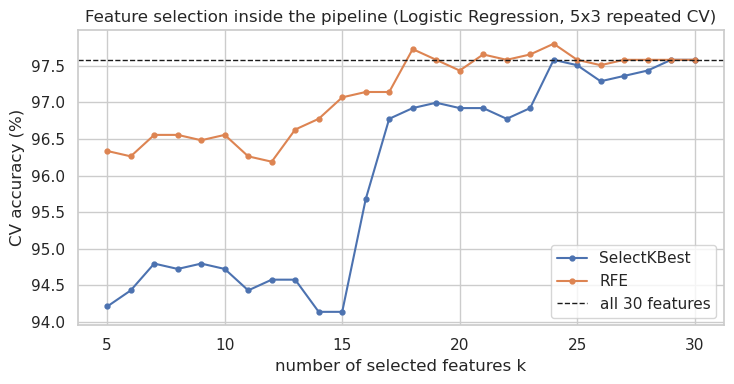

In [11]:
ks = list(range(5, 31))
curve = {}
for name, make_sel in {'SelectKBest': lambda k: SelectKBest(f_classif, k=k),
                       'RFE': lambda k: RFE(lr(), n_features_to_select=k)}.items():
    res = [cv_scores(make_pipe(lr(), make_sel(k))) for k in ks]
    curve[name] = pd.DataFrame({'k': ks, 'mean': [r.mean() for r in res], 'std': [r.std() for r in res]}).set_index('k')
baseline = cv_scores(make_pipe(lr()))
print(f'All 30 features: {baseline.mean():.2%} +/- {baseline.std():.2%}')

def one_se_k(c, n_scores=15):
    """Smallest k whose mean CV accuracy is within one standard error of the best k."""
    best = c['mean'].idxmax(); se = c.loc[best, 'std'] / np.sqrt(n_scores)
    return int(c.index[c['mean'] >= c.loc[best, 'mean'] - se][0]), int(best)

k_se = {}
for name, c in curve.items():
    k_se[name], k_best = one_se_k(c)
    print(f'{name:12s} best k = {k_best} ({c.loc[k_best, "mean"]:.2%});  1-SE rule picks k = {k_se[name]} ({c.loc[k_se[name], "mean"]:.2%})')

fig, ax = plt.subplots(figsize=(7.5, 4))
for name, c in curve.items():
    ax.plot(c.index, c['mean'] * 100, marker='o', ms=3.5, label=name)
ax.axhline(baseline.mean() * 100, color='k', ls='--', lw=1, label='all 30 features')
ax.set_xlabel('number of selected features k'); ax.set_ylabel('CV accuracy (%)')
ax.set_title('Feature selection inside the pipeline (Logistic Regression, 5x3 repeated CV)'); ax.legend()
plt.tight_layout()
plt.show()

With all 30 features the accuracy is 97.6 % (± 1.4 pp). SelectKBest needs about 24 features to reach this level and is worse for small k (about 94-95 % for k <= 15). RFE is better for small k (about 96.5 % with only 5-10 features) and peaks at 97.8 % for k=24; the 1-SE rule gives k=18. SelectKBest ranks features one by one by their F-score. Since radius, perimeter and area (mean/worst) all have almost the same, very high score, they take most of the first slots and add no new information. RFE removes features recursively using the model's coefficients and therefore copes better with redundancy.

The accuracy at the best k is estimated on the same folds that were used to choose k, which is again slightly optimistic. Nested CV (inner loop selects k, outer loop scores) avoids that:

In [12]:
# Honest estimate of "choose k by CV, then score it": nested cross-validation (inner loop picks k, outer loop scores).
outer = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)
inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
k_grid = [5, 10, 15, 20, 25, 30]
nested = {}
for name, sel, param in [('SelectKBest', SelectKBest(f_classif), 'select__k'),
                         ('RFE', RFE(lr()), 'select__n_features_to_select')]:
    gs = GridSearchCV(make_pipe(lr(), sel), {param: k_grid}, cv=inner)
    nested[name] = cross_val_score(gs, X_train, y_train, cv=outer)
    print(f'{name:12s} nested CV accuracy (k tuned inside): {nested[name].mean():.2%} +/- {nested[name].std():.2%}')

SelectKBest  nested CV accuracy (k tuned inside): 97.47% +/- 1.63%
RFE          nested CV accuracy (k tuned inside): 97.25% +/- 1.92%


Nested CV gives 97.5 % (SelectKBest) and 97.3 % (RFE), with standard deviations of about 1.6-1.9 pp. So tuning the number of features does not beat using all 30 features (97.6 %); the differences are far smaller than the fold-to-fold variation.

### 4.3 Comparing feature sets

For every strategy the table shows the number of features kept (when fitted on the whole training set), the CV accuracy, and how much redundancy remains in the kept set (number of pairs with |r| > 0.9 and the largest |r|). Besides the two selectors and their intersection (the idea of the first version, with the k values that the first version chose: 19 and 17), a correlation filter is added: features are visited from the most to the least discriminative and a feature is kept only if it is not correlated above the threshold with any feature already kept.

In [13]:
def fitted_mask(selector):
    return make_pipe(lr(), selector).fit(X_train, y_train).named_steps['select'].get_support()

def redundancy(mask):
    c = np.abs(np.corrcoef(X_train[:, mask], rowvar=False)); iu = np.triu_indices(mask.sum(), 1)
    return int((c[iu] > 0.90).sum()), c[iu].max()

strategies = {
    'All 30 features (no selection)':              None,
    'SelectKBest ∩ RFE (original subset: k=19 / k=17)': IntersectionSelector(19, 17),
    f'SelectKBest, k={k_se["SelectKBest"]} (1-SE rule)': SelectKBest(f_classif, k=k_se['SelectKBest']),
    f'RFE, k={k_se["RFE"]} (1-SE rule)':             RFE(lr(), n_features_to_select=k_se['RFE']),
    'Correlation filter, |r| <= 0.95':             CorrelationFilter(0.95),
    'Correlation filter, |r| <= 0.90':             CorrelationFilter(0.90),
}
rows, masks = [], {}
for name, sel in strategies.items():
    sc = cv_scores(make_pipe(lr(), sel))
    if sel is None:
        mask = np.ones(30, dtype=bool)
    else:
        mask = fitted_mask(sel); masks[name] = mask
    n_pairs, max_r = redundancy(mask)
    rows.append({'Feature set': name, '# features': int(mask.sum()), 'CV accuracy (%)': sc.mean() * 100,
                 'CV std (pp)': sc.std() * 100, 'pairs |r|>0.9': n_pairs, 'max |r|': max_r})
fs_table = pd.DataFrame(rows).set_index('Feature set')
fs_table.round({'CV accuracy (%)': 2, 'CV std (pp)': 2, 'max |r|': 3})

,# features,CV accuracy (%),CV std (pp),pairs |r|>0.9,max |r|
Feature set,,,,,
All 30 features (no selection),30,97.58,1.40,21,0.998
SelectKBest ∩ RFE (original subset: k=19 / k=17),16,96.78,1.63,16,0.994
"SelectKBest, k=24 (1-SE rule)",24,97.58,1.51,21,0.998
"RFE, k=18 (1-SE rule)",18,97.73,1.23,16,0.994
"Correlation filter, |r| <= 0.95",23,97.22,1.38,3,0.921
"Correlation filter, |r| <= 0.90",21,97.29,1.19,0,0.897



* The intersection of SelectKBest and RFE, the 16-feature subset of the first version, reaches 96.8 % CV accuracy (± 1.6 pp) against 97.6 % for all 30 features. The loss of about 0.8 pp is within the fold-to-fold spread, so the subset is not worse, but it is not better either, and the claim of the first version that feature selection "works" rested partly on the leaky evaluation.
* The univariate and RFE subsets: they still contain 16 (intersection and RFE) to 21 (SelectKBest, the same as the full set) strongly correlated pairs, and the maximum |r| stays at 0.99 or above. "Both methods agree" does not mean "optimal" or "non-redundant"; agreement is mostly due to both methods favouring the same large-scale geometric features.
* The correlation filter is the only strategy that actually removes redundancy (0 pairs above 0.9 with threshold 0.90, 3 pairs at 0.95) and it does so at essentially no cost: 21 features give 97.3 % against 97.6 % for all 30, which is well inside one standard deviation (1.2-1.4 pp). It is therefore used as the "reduced" feature set in Section 5.

The table marks, for each of the 10 properties and each of mean / se / worst, whether the feature is retained (selectors fitted on the whole training set).

In [14]:
def family_table(mask):
    t = pd.DataFrame(mask.reshape(3, 10).T, index=base_props, columns=stats)
    return t.replace({True: '●', False: ''})

inter_key = 'SelectKBest ∩ RFE (original subset: k=19 / k=17)'
corr_key = 'Correlation filter, |r| <= 0.90'
pd.concat({'SelectKBest ∩ RFE (original)': family_table(masks[inter_key]),
           'Correlation filter (0.90)': family_table(masks[corr_key])}, axis=1)

SelectKBest ∩ RFE (original)          Correlation filter (0.90)         
                                          mean se worst                      mean se worst
radius                                       ●  ●     ●                            ●      
texture                                      ●        ●                            ●     ●
perimeter                                       ●     ●                                  ●
area                                         ●  ●     ●                                   
smoothness                                            ●                         ●  ●     ●
compactness                                                                     ●  ●     ●
concavity                                    ●        ●                         ●  ●     ●
concave_points                               ●        ●                            ●     ●
symmetry                                              ●                         ●  ●     ●
fractal_dimension                                                               ●  ●     ●

The intersection between SelectKBest and RFE subset (16 features) is dominated by the size family: radius (mean, se, worst), area (mean, se, worst) and perimeter (se, worst), plus texture (mean, worst), concavity and concave points (mean, worst), and one feature each from smoothness and symmetry; compactness and fractal dimension are absent. This is consistent with the effect sizes in Section 3.3 (the size and concavity features discriminate best), but it is exactly the group with the highest redundancy: radius, perimeter and area are kept together, which is why 16 strongly correlated pairs remain. The correlation filter (21 features) does the opposite: it keeps only `radius_se` and `perimeter_worst` from the size group and drops `area` completely, but keeps nearly all shape descriptors (smoothness, compactness, concavity, symmetry and fractal dimension), which are not strongly correlated with the size features or with each other. Some of these (e.g. fractal dimension) discriminate poorly on their own, which is the price of the filter. Which set is preferable depends on the goal: a small, highly discriminative but redundant set (selectors), or a non-redundant set with similar accuracy (filter).

## 5. Comparison between the classification algorithms

Seven algorithms are compared, each inside the pipeline `StandardScaler -> [feature filter] -> classifier`:  Logistic Regression, LDA, k-NN, SVM, Gaussian Naive Bayes, CART and Random Forest. Positive class = malignant, so recall is the sensitivity to malignant cases and a false negative (FN) is a missed malignant tumour.

### 5.1 Hyperparameter grids

The table counts the grid sizes (the number of candidate settings; the SVM grid contains gamma values that have no effect for the linear kernel, so its effective size is smaller). Note that the SVM grid (18 settings) is smaller than the Random Forest grid (72).

In [15]:
models = {
    'Logistic Regression': (LogisticRegression(max_iter=5000), [
        {'clf__solver': ['liblinear'], 'clf__penalty': ['l1', 'l2'], 'clf__C': [0.001, 0.01, 0.1, 1, 10, 100]},
        {'clf__solver': ['lbfgs'], 'clf__penalty': ['l2'], 'clf__C': [0.001, 0.01, 0.1, 1, 10, 100]}]),
    'Linear Discriminant Analysis': (LinearDiscriminantAnalysis(), {'clf__solver': ['svd', 'lsqr']}),
    'K-Nearest Neighbors': (KNeighborsClassifier(), {'clf__n_neighbors': [3, 5, 7, 9, 11],
                                                     'clf__weights': ['uniform', 'distance'],
                                                     'clf__metric': ['euclidean', 'manhattan']}),
    'Support Vector Machine': (SVC(probability=True, random_state=SEED), {'clf__C': [0.1, 1, 10],
                                                                           'clf__kernel': ['linear', 'rbf', 'poly'],
                                                                           'clf__gamma': ['scale', 'auto']}),
    'Gaussian Naive Bayes': (GaussianNB(), {}),
    'CART': (DecisionTreeClassifier(random_state=SEED), {'clf__max_depth': [None, 5, 10, 20],
                                                         'clf__min_samples_split': [2, 5, 10],
                                                         'clf__criterion': ['gini', 'entropy']}),
    'Random Forest': (RandomForestClassifier(random_state=SEED), {'clf__n_estimators': [100, 300, 500],
                                                                  'clf__max_depth': [None, 5, 10, 20],
                                                                  'clf__min_samples_split': [2, 5, 10],
                                                                  'clf__max_features': ['sqrt', 'log2']}),
}
grid_size = {n: (len(ParameterGrid(g)) if g else 0) for n, (_, g) in models.items()}
pd.DataFrame({'candidate settings': grid_size,
              'fits in 5-fold CV': {n: s * 5 for n, s in grid_size.items()}})

,candidate settings,fits in 5-fold CV
Logistic Regression,18,90
Linear Discriminant Analysis,2,10
K-Nearest Neighbors,20,100
Support Vector Machine,18,90
Gaussian Naive Bayes,0,0
CART,24,120
Random Forest,72,360


### 5.2 Default hyperparameters (all 30 features)

The boxplot shows the 15 CV scores per model (5-fold, 3 repeats).

                              mean (%)  std (pp)
Logistic Regression              97.58      1.40
Linear Discriminant Analysis     95.31      1.98
K-Nearest Neighbors              96.41      2.42
Support Vector Machine           97.14      1.49
Gaussian Naive Bayes             93.85      2.56
CART                             92.16      3.03
Random Forest                    95.75      2.66


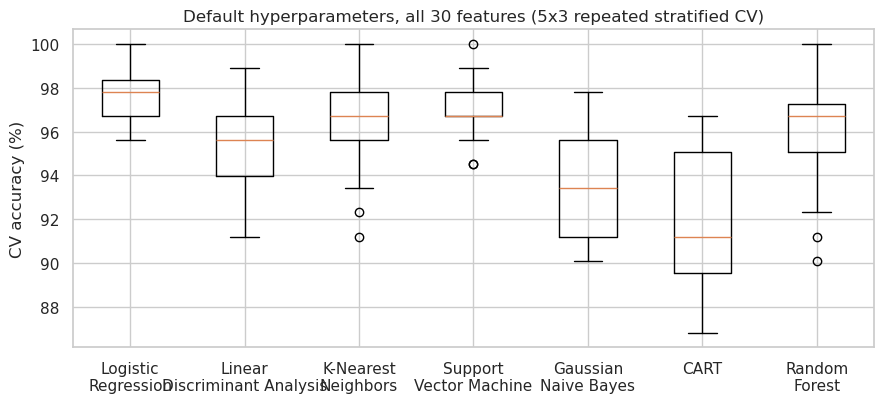

In [16]:
default_cv = {}
for name, (clf, _) in models.items():
    default_cv[name] = cv_scores(make_pipe(clf))
default_tbl = pd.DataFrame({n: {'mean (%)': s.mean() * 100, 'std (pp)': s.std() * 100} for n, s in default_cv.items()}).T
print(default_tbl.round(2).to_string())

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.boxplot([s * 100 for s in default_cv.values()], tick_labels=[n.replace(' ', '\n', 1) for n in default_cv])
ax.set_ylabel('CV accuracy (%)'); ax.set_title('Default hyperparameters, all 30 features (5x3 repeated stratified CV)')
plt.tight_layout()
plt.show()

With default settings, Logistic Regression (97.6 %) and the SVM (97.1 %, RBF kernel by default) are best, followed by k-NN (96.4 %), Random Forest (95.8 %), LDA (95.3 %), Gaussian NB (93.9 %) and CART (92.2 %). The standard deviations are 1.4-3.0 pp, so the top models are statistically indistinguishable and only the gap to CART and Gaussian NB is clear. Note that the SVM is a nonlinear mode; the linear models in this comparison are Logistic Regression and LDA.

### 5.3 GridSearchCV vs. RandomizedSearchCV (SVM)

To check how much tuning effort is needed, a grid is compared with a randomised search that tries only 8 of the 18 settings.

In [17]:
svm_clf, svm_grid = models['Support Vector Machine']
t0 = time.time()
gs_svm = GridSearchCV(make_pipe(svm_clf), svm_grid, cv=5, scoring='accuracy').fit(X_train, y_train)
t_grid = time.time() - t0
t0 = time.time()
rs_svm = RandomizedSearchCV(make_pipe(svm_clf), svm_grid, n_iter=8, cv=5, scoring='accuracy', random_state=SEED).fit(X_train, y_train)
t_rand = time.time() - t0
pd.DataFrame({'settings tried': [len(gs_svm.cv_results_['params']), 8],
              'best CV accuracy (%)': [gs_svm.best_score_ * 100, rs_svm.best_score_ * 100],
              'time (s)': [t_grid, t_rand],
              'best parameters': [str({k.replace('clf__', ''): v for k, v in gs_svm.best_params_.items()}),
                                  str({k.replace('clf__', ''): v for k, v in rs_svm.best_params_.items()})]},
             index=['GridSearchCV', 'RandomizedSearchCV']).round(2)

,settings tried,best CV accuracy (%),time (s),best parameters
GridSearchCV,18,97.36,1.26,"{'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}"
RandomizedSearchCV,8,97.36,0.55,"{'kernel': 'rbf', 'gamma': 'scale', 'C': 10}"


Both searches reach the same best CV accuracy (97.4 %) and both choose an RBF kernel, but the randomised search is about twice as fast (0.5 s against 1.1 s).

### 5.4 Tuned models on the held-out test set

Models with non-empty hyperparameter grids are tuned using `GridSearchCV` (5-fold stratified CV on the training set, accuracy), and the best pipeline is evaluated once on the test samples. Gaussian Naive Bayes has no hyperparameter grid, so it is fitted with its default settings. Its cross-validation accuracy is calculated separately using the same stratified folds. This is done twice: with all 30 features and with the reduced feature set from Section 4 (correlation filter, |r| ≤ 0.90, applied inside the pipeline). Tables are sorted by test accuracy; `CV acc.` is the best cross-validated accuracy found during tuning, or the default-model CV accuracy for Gaussian Naive Bayes. One test sample corresponds to 0.9 pp of accuracy and, because the test set has 42 malignant cases, to 2.4 pp of recall.

**Tuned models, all 30 features**

In [18]:
def evaluate(est, X_te, y_te):
    pred, proba = est.predict(X_te), est.predict_proba(X_te)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    return {'Accuracy': accuracy_score(y_te, pred), 'Precision': precision_score(y_te, pred),
            'Recall': recall_score(y_te, pred), 'F1': f1_score(y_te, pred), 'MCC': matthews_corrcoef(y_te, pred),
            'AUC': roc_auc_score(y_te, proba), 'FN': int(fn), 'FP': int(fp)}, proba

feature_sets = {'All 30 features': None, 'Reduced (corr. filter 0.90)': CorrelationFilter(0.90)}
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
fitted, test_rows, tuned_cv, best_params, probas = {}, [], {}, {}, {}

t0 = time.time()
for fs_name, sel in feature_sets.items():
    for name, (clf, grid) in models.items():
        if grid:
            gs = GridSearchCV(make_pipe(clf, sel), grid, cv=inner_cv, scoring='accuracy').fit(X_train, y_train)
            est, cv_acc = gs.best_estimator_, gs.best_score_
            best_params[(fs_name, name)] = {k.replace('clf__', ''): v for k, v in gs.best_params_.items()}
        else:
            est = clone(make_pipe(clf, sel)).fit(X_train, y_train)
            cv_acc = cross_val_score(
    make_pipe(clf, sel),
    X_train,
    y_train,
    cv=inner_cv,
    scoring='accuracy'
).mean()
            best_params[(fs_name, name)] = {}
        metrics, proba = evaluate(est, X_test, y_test)
        fitted[(fs_name, name)], probas[(fs_name, name)], tuned_cv[(fs_name, name)] = est, proba, cv_acc
        test_rows.append({'Feature set': fs_name, 'Model': name, 'CV accuracy': cv_acc, **metrics})
print(f'Tuning and test evaluation finished in {(time.time() - t0) / 60:.1f} min')
test_df = pd.DataFrame(test_rows)

Tuning and test evaluation finished in 6.4 min


Test results are shown below.

In [19]:
def show(fs_name):
    t = test_df[test_df['Feature set'] == fs_name].set_index('Model').drop(columns='Feature set')
    t = t.sort_values(['Accuracy', 'MCC'], ascending=False)
    for c in ['CV accuracy', 'Accuracy', 'Precision', 'Recall', 'F1']:
        t[c] = (t[c] * 100).round(1)
    t['MCC'] = t['MCC'].round(2); t['AUC'] = t['AUC'].round(3)
    return t.rename(columns={'CV accuracy': 'CV acc. (%)', 'Accuracy': 'Test acc. (%)', 'Precision': 'Prec. (%)',
                             'Recall': 'Recall (%)', 'F1': 'F1 (%)'})
show('All 30 features')

,CV acc. (%),Test acc. (%),Prec. (%),Recall (%),F1 (%),MCC,AUC,FN,FP
Model,,,,,,,,,
Logistic Regression,97.4,98.2,100.0,95.2,97.6,0.96,0.998,2,0
Support Vector Machine,97.6,97.4,100.0,92.9,96.3,0.94,0.993,3,0
Random Forest,96.7,97.4,100.0,92.9,96.3,0.94,0.995,3,0
Linear Discriminant Analysis,95.6,96.5,100.0,90.5,95.0,0.93,0.997,4,0
K-Nearest Neighbors,97.6,96.5,100.0,90.5,95.0,0.93,0.974,4,0
CART,93.0,95.6,97.4,90.5,93.8,0.91,0.966,4,1
Gaussian Naive Bayes,93.8,92.1,92.3,85.7,88.9,0.83,0.989,6,3


**Tuned models, reduced feature set (21 features, correlation filter)**

In [20]:
show('Reduced (corr. filter 0.90)')

,CV acc. (%),Test acc. (%),Prec. (%),Recall (%),F1 (%),MCC,AUC,FN,FP
Model,,,,,,,,,
Support Vector Machine,96.9,97.4,100.0,92.9,96.3,0.94,0.993,3,0
Linear Discriminant Analysis,95.2,96.5,100.0,90.5,95.0,0.93,0.996,4,0
Random Forest,96.7,96.5,100.0,90.5,95.0,0.93,0.995,4,0
Logistic Regression,97.6,96.5,97.5,92.9,95.1,0.92,0.997,3,1
K-Nearest Neighbors,96.7,94.7,97.4,88.1,92.5,0.89,0.953,5,1
CART,91.9,93.0,92.5,88.1,90.2,0.85,0.920,5,3
Gaussian Naive Bayes,91.9,89.5,87.5,83.3,85.4,0.77,0.976,7,5


With all 30 features Logistic Regression is first (98.2 %), then SVM and Random Forest (97.4 %), LDA and k-NN (96.5 %), CART (95.6 %) and Gaussian NB (92.1 %). With the reduced set the SVM (97.4 %) and LDA (96.5 %) are unchanged, Random Forest and Logistic Regression drop to 96.5 %, k-NN to 94.7 %, CART to 93.0 % and Gaussian NB to 89.5 %. The CV accuracy used for tuning shows a flatter picture, so most test differences between the two feature sets are one to three samples.

Selected hyperparameters (all 30 features):

In [21]:
params_df = pd.DataFrame([{'Model': n, 'Selected hyperparameters (all 30 features)': str(p) if p else '-'}
                          for (fs, n), p in best_params.items() if fs == 'All 30 features']).set_index('Model')
pd.set_option('display.max_colwidth', 120)
params_df

,Selected hyperparameters (all 30 features)
Model,
Logistic Regression,"{'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}"
Linear Discriminant Analysis,{'solver': 'svd'}
K-Nearest Neighbors,"{'metric': 'manhattan', 'n_neighbors': 3, 'weights': 'uniform'}"
Support Vector Machine,"{'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}"
Gaussian Naive Bayes,-
CART,"{'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 10}"
Random Forest,"{'max_depth': 5, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 100}"


### 5.5 ROC, precision-recall curves and confusion matrices (30 features)

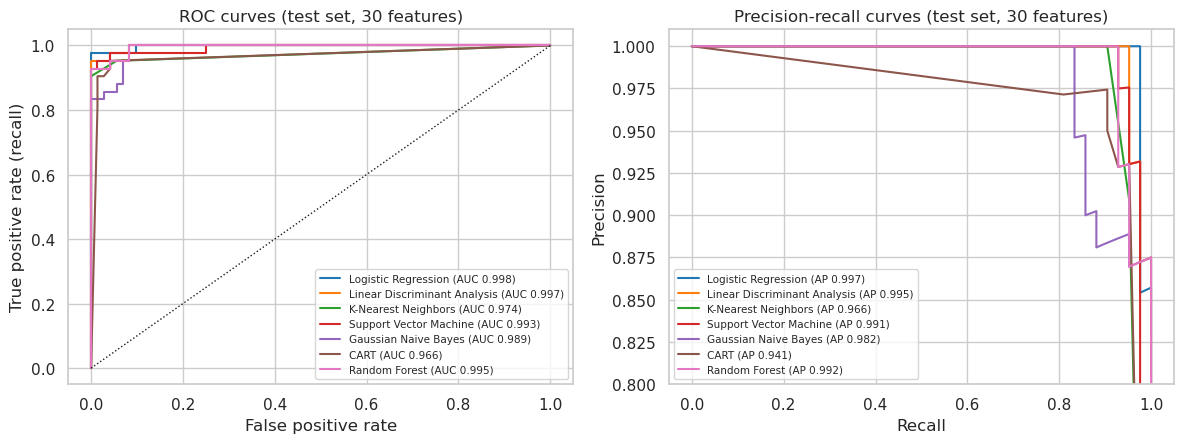

In [22]:
fs = 'All 30 features'
palette = sns.color_palette('tab10', len(models))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for (name, _), col in zip(models.items(), palette):
    p = probas[(fs, name)]
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=col, label=f'{name} (AUC {roc_auc_score(y_test, p):.3f})')
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, color=col, label=f'{name} (AP {average_precision_score(y_test, p):.3f})')
axes[0].plot([0, 1], [0, 1], 'k:', lw=1)
axes[0].set(xlabel='False positive rate', ylabel='True positive rate (recall)', title='ROC curves (test set, 30 features)')
axes[1].set(xlabel='Recall', ylabel='Precision', title='Precision-recall curves (test set, 30 features)', ylim=(0.8, 1.01))
axes[0].legend(fontsize=7.5, loc='lower right'); axes[1].legend(fontsize=7.5, loc='lower left')
plt.tight_layout()
fig.savefig('plots/roc_pr_curves.png', dpi=200, bbox_inches='tight')
plt.show()

All curves are close to the top-left corner: AUC is at least 0.97 for every model except CART, whose single tree produces few distinct probabilities (AUC 0.966). The precision-recall curves are consistent with the results.

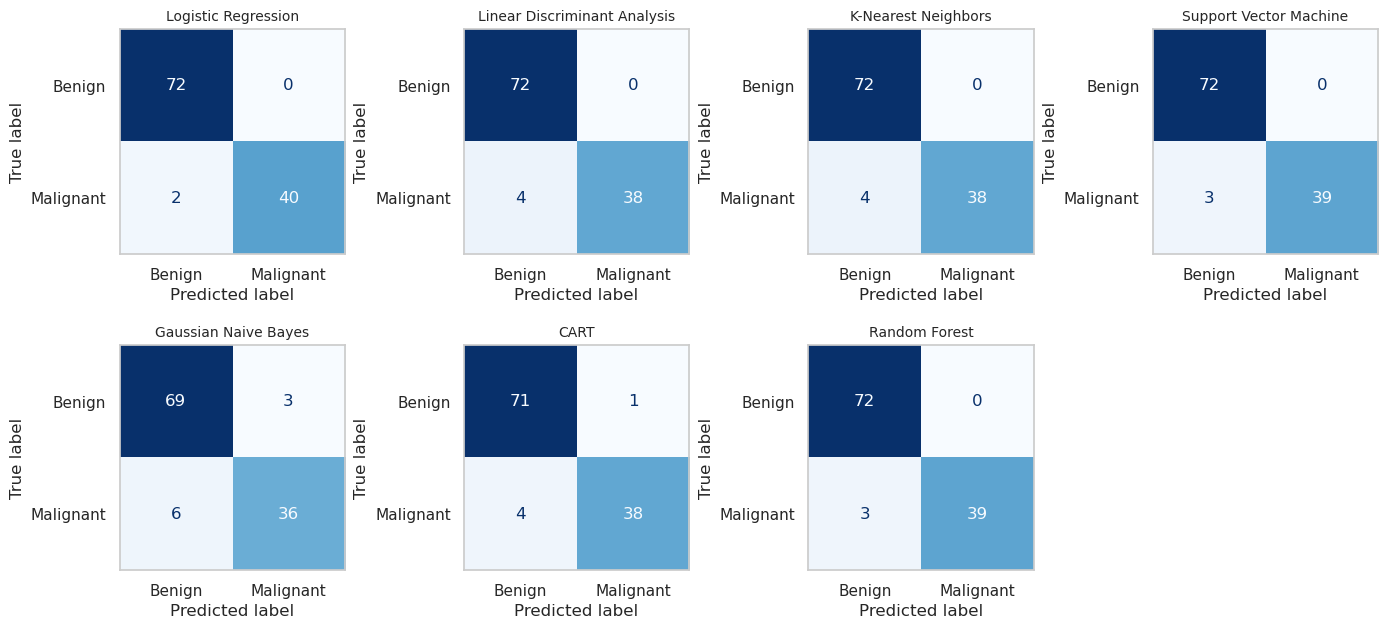

In [23]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6.5))
for ax, (name, _) in zip(axes.ravel(), models.items()):
    pred = fitted[(fs, name)].predict(X_test)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['Benign', 'Malignant']).plot(
        ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name, fontsize=10); ax.grid(False)
axes.ravel()[-1].axis('off')
plt.tight_layout()
fig.savefig('plots/confusion_matrices.png', dpi=200, bbox_inches='tight')
plt.show()

Every model except Gaussian NB and CART has no false positive, so no benign case is wrongly called malignant; all errors are malignant cases predicted as benign. Logistic Regression misses 2 of 42 malignant cases, the SVM and Random Forest 3, LDA and k-NN 4, CART 4 (plus 1 FP) and Gaussian NB 6 (plus 3 FP). In a medical screening context a missed malignant case is the costly error, which is why recall and the FN count are more informative than accuracy alone; this also suggests that the decision threshold could be lowered (accepting a few more false alarms) if sensitivity matters most.

## 6. Summary of results

Each column belongs to one experiment (see the table in the introduction): *Default, CV* = default hyperparameters, repeated CV on the training set; *Tuned, CV* = best CV score during tuning; *Tuned, test* = accuracy on the held-out test set, with all 30 features and with the reduced set; the last column counts the malignant test cases that were missed with the 30-feature model.

In [24]:
summary_df = pd.DataFrame({
    'Default, CV (30 feat.)': default_tbl['mean (%)'],
    'Tuned, CV (30 feat.)': {n: tuned_cv[('All 30 features', n)] * 100 for n in models},
    'Tuned, test (30 feat.)': {n: test_df[(test_df['Feature set'] == 'All 30 features') & (test_df.Model == n)].Accuracy.iloc[0] * 100 for n in models},
    'Tuned, test (reduced)': {n: test_df[(test_df['Feature set'] != 'All 30 features') & (test_df.Model == n)].Accuracy.iloc[0] * 100 for n in models},
    'Missed malignant (30 feat.)': {n: int(test_df[(test_df['Feature set'] == 'All 30 features') & (test_df.Model == n)].FN.iloc[0]) for n in models},
}).sort_values('Tuned, test (30 feat.)', ascending=False)
summary_df.round(1)

,"Default, CV (30 feat.)","Tuned, CV (30 feat.)","Tuned, test (30 feat.)","Tuned, test (reduced)",Missed malignant (30 feat.)
Logistic Regression,97.6,97.4,98.2,96.5,2
Random Forest,95.8,96.7,97.4,96.5,3
Support Vector Machine,97.1,97.6,97.4,97.4,3
K-Nearest Neighbors,96.4,97.6,96.5,94.7,4
Linear Discriminant Analysis,95.3,95.6,96.5,96.5,4
CART,92.2,93.0,95.6,93.0,4
Gaussian Naive Bayes,93.8,93.8,92.1,89.5,6


In [25]:
test_df.to_csv('results/results_tuned_models_test.csv', index=False)
summary_df.round(2).to_csv('results/summary_by_model.csv', index_label='Model')
fs_table.round(4).to_csv('results/feature_selection_experiment.csv')
default_tbl.round(3).to_csv('results/default_models_cv.csv', index_label='Model')
for (fs_name, name), est in fitted.items():
    tag = 'all30' if fs_name.startswith('All') else 'reduced'
    joblib.dump(est, f'models/{name.replace(" ", "_").lower()}_{tag}.joblib')
print('Saved results/, models/ and plots/')

Saved results/, models/ and plots/


## 7. Conclusions

Logistic Regression (C=0.1, L2, liblinear) has the best test accuracy with all 30 features: 98.2 % (112 of 114 correct), recall 95.2 %, precision 100 %, MCC 0.96, AUC 0.998. The SVM (RBF kernel, C=10) and Random Forest follow with 97.4 %. These differences correspond to one or two test samples, so they are not statistically meaningful: the CV scores of the top models differ by less than their standard deviation (about 1.4-2 pp). Well-tuned simple and flexible models reach about the same performance, and that Gaussian NB and CART are clearly weaker.

Logistic Regression and the nonlinear RBF SVM perform about equally, while the other linear model (LDA) is slightly worse. The PCA plot and these results indicate a nearly linearly separable problem, but the data do not show that nonlinear models are worse: the selected SVM is nonlinear and performs at the same level.

After removing the leakage, selecting a subset with SelectKBest, RFE or their intersection does not improve on the full 30-feature set; the 16-feature subset of the first version gives 96.8 % CV accuracy against 97.6 % (within the fold-to-fold spread), and it still contains 16 strongly correlated pairs. A correlation filter is the only method that removes the redundancy, and it costs very little (21 features: 97.3 % CV against 97.6 %), although the test accuracy of most models is slightly lower with the reduced set (e.g. Logistic Regression 96.5 % against 98.2 %, k-NN 94.7 % against 96.5 %); the SVM is unchanged. Since all differences are within one to three test samples, the conservative conclusion is that the full feature set is a safe default and the reduced set a reasonable choice if interpretability or redundancy matters.

All errors of the best models are missed malignant cases (FN), not false alarms; 2-4 of 42 malignant cases were missed. For a diagnostic tool this error type matters most, so sensitivity should be optimised and reported along with accuracy.

The dataset is small and comes from a single source. The metrics rest on a single 80/20 split, so differences of one or two samples are within noise; repeated or nested CV for all tuned models would give tighter comparisons. No transformation of the skewed features and no threshold tuning were tried. An independent dataset would be needed to confirm that the results are not overfitting.

Tables are saved in `results/`, figures in `plots/` and the fitted pipelines in `models/` (to load them with `joblib.load`, first run the first cell of this notebook, which defines the two custom selectors).